# 05 — Forecasting and Validation

Chronological forecasting evaluation and validation checks.

## 1. Forecasting objective

Compare a previous-month baseline with a three-month moving average using chronological one-step-ahead evaluation.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "reports").exists():
    ROOT = Path.cwd().parent

REPORTS = ROOT / "reports"
PROCESSED = ROOT / "data" / "processed"
FIGURES = REPORTS / "figures"

print("Project root:", ROOT)
print("Reports directory exists:", REPORTS.exists())
print("Processed data directory exists:", PROCESSED.exists())

Project root: C:\Users\tadij\Documents\retail-customer-intelligence-python
Reports directory exists: True
Processed data directory exists: True


## 2. Monthly sales history

In [2]:
monthly = pd.read_csv(REPORTS / "monthly_sales.csv")
monthly["month"] = pd.to_datetime(monthly["month"])
display(monthly)

print(
    "The December 2011 observation is incomplete and is excluded "
    "from the forecasting evaluation."
)

,month,sales_value,mom_growth_percent
0,2010-12-01,748957.020,NaN
1,2011-01-01,560000.260,-25.23
2,2011-02-01,498062.650,-11.06
3,2011-03-01,683267.080,37.18
4,2011-04-01,493207.121,-27.82
5,2011-05-01,723333.510,46.66
6,2011-06-01,691123.120,-4.45
7,2011-07-01,681300.111,-1.42
8,2011-08-01,682680.510,0.20
9,2011-09-01,1019687.622,49.37


The December 2011 observation is incomplete and is excluded from the forecasting evaluation.


## 3. Forecast predictions and metrics

In [3]:
predictions = pd.read_csv(REPORTS / "forecast_predictions.csv")
metrics = pd.read_csv(REPORTS / "forecast_model_evaluation.csv")

display(predictions)
display(metrics)

,month,actual_sales,previous_month_baseline,three_month_moving_average,training_months
0,2011-04,493207.121,683267.080,580443.330000,4
1,2011-05,723333.510,493207.121,558178.950333,5
2,2011-06,691123.120,723333.510,633269.237000,6
3,2011-07,681300.111,691123.120,635887.917000,7
4,2011-08,682680.510,681300.111,698585.580333,8
5,2011-09,1019687.622,682680.510,685034.580333,9
6,2011-10,1070704.670,1019687.622,794556.081000,10
7,2011-11,1461756.250,1070704.670,924357.600667,11


,model,evaluation_months,mae,rmse
0,Previous-month baseline,8,155334.48575,211930.035656
1,Three-month moving average,8,189970.27450,254361.088060


## 4. Forecast visualization

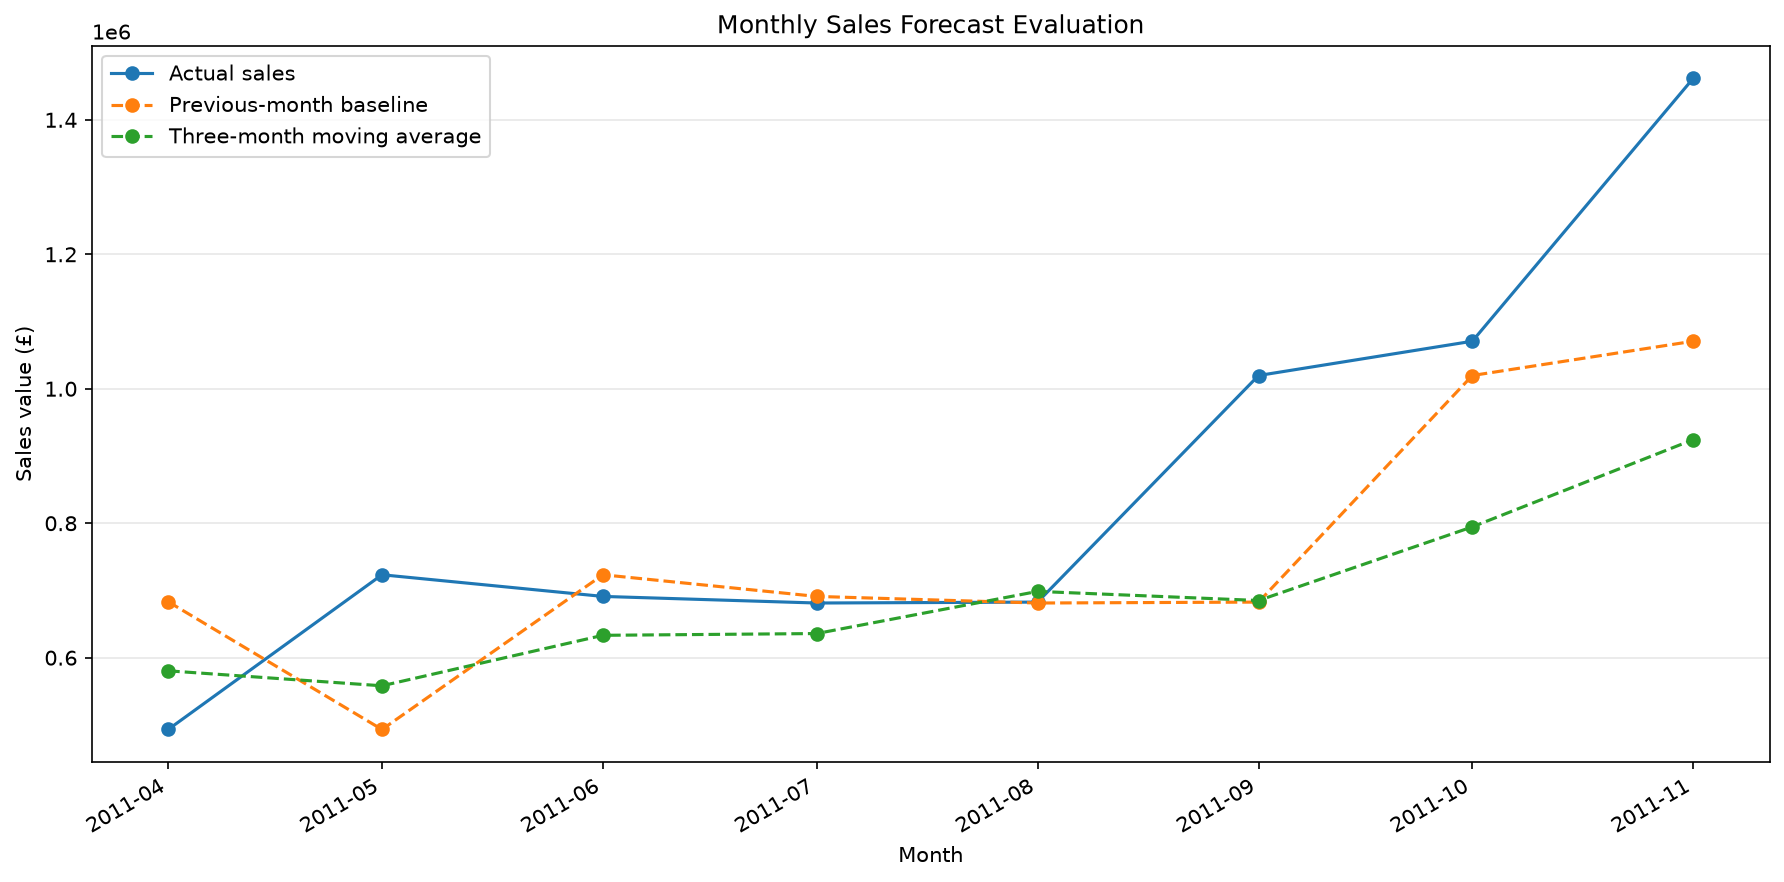

In [4]:
chart = FIGURES / "forecast_evaluation.png"
if chart.exists():
    from IPython.display import Image, display as show_image
    show_image(Image(filename=str(chart)))

## 5. Validation and limitations

Predictions use only data available before each target month. The evaluation has only eight test months, so the results are uncertain. The previous-month baseline performed better on this sample, but this does not guarantee better future performance. Annual seasonality cannot be established reliably from this short history.

In [5]:
assert not predictions["month"].astype(str).str.endswith("-12").any()
assert predictions["month"].is_unique
assert predictions["actual_sales"].notna().all()
assert metrics["mae"].notna().all()
assert metrics["rmse"].notna().all()

print("Forecast validation checks passed.")

Forecast validation checks passed.
